# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [1]:
# run this first if you dont have them installed in your env
%pip install pandas numpy matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [3]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()
print("Data shape: ", df.shape)
print("Duplicates: ", df.duplicated().sum())
print("NA values: \n", df.isna().sum())

clean = df.copy()
clean = clean.drop_duplicates()
clean = clean.dropna()

#check the cleaned data
print("Data shape after cleaning: ", clean.shape)
print("Duplicates after cleaning: ", clean.duplicated().sum())
print("NA values after cleaning: \n", clean.isna().sum())

Data shape:  (11914, 15)
Duplicates:  720
NA values: 
 Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64
Data shape after cleaning:  (11092, 15)
Duplicates after cleaning:  0
NA values after cleaning: 
 Make                 0
Model                0
Year                 0
Engine Fuel Type     0
Engine HP            0
Engine Cylinders     0
Transmission Type    0
Driven_Wheels        0
Number of Doors      0
Vehicle Size         0
Vehicle Style        0
highway MPG          0
city mpg             0
Popularity           0
MSRP                 0
dtype: int64


In [4]:
print (clean["Driven_Wheels"].value_counts(dropna=False), "\n")
print (clean["Number of Doors"].value_counts(dropna=False), "\n")
print (clean["Vehicle Size"].value_counts(dropna=False), "\n")

#this data looks okay

Driven_Wheels
front wheel drive    4295
rear wheel drive     3181
all wheel drive      2291
four wheel drive     1325
Name: count, dtype: int64 

Number of Doors
4.0    7866
2.0    2870
3.0     356
Name: count, dtype: int64 

Vehicle Size
Compact    4337
Midsize    4101
Large      2654
Name: count, dtype: int64 



In [5]:
print (clean["Vehicle Style"].value_counts(dropna=False), "\n")

#data looks okay

Vehicle Style
Sedan                  2805
4dr SUV                2426
Coupe                  1154
Convertible             741
Crew Cab Pickup         654
4dr Hatchback           639
Extended Cab Pickup     597
Wagon                   557
2dr Hatchback           408
Passenger Minivan       384
Regular Cab Pickup      345
Passenger Van           121
2dr SUV                  91
Cargo Van                84
Cargo Minivan            58
Convertible SUV          28
Name: count, dtype: int64 



In [6]:
print (clean["Engine Fuel Type"].value_counts(dropna=False), "\n")
print (clean["Transmission Type"].value_counts(dropna=False), "\n")

#transmission types unknown value, maybe set to NaN or drop
clean["Transmission Type"] = clean["Transmission Type"].replace("UNKNOWN", np.nan)
clean = clean.dropna()
print (clean["Transmission Type"].value_counts(dropna=False), "\n")


Engine Fuel Type
regular unleaded                                6636
premium unleaded (required)                     1938
premium unleaded (recommended)                  1388
flex-fuel (unleaded/E85)                         887
diesel                                           149
flex-fuel (premium unleaded required/E85)         53
flex-fuel (premium unleaded recommended/E85)      26
electric                                          13
natural gas                                        2
Name: count, dtype: int64 

Transmission Type
AUTOMATIC           7893
MANUAL              2620
AUTOMATED_MANUAL     552
DIRECT_DRIVE          15
UNKNOWN               12
Name: count, dtype: int64 

Transmission Type
AUTOMATIC           7893
MANUAL              2620
AUTOMATED_MANUAL     552
DIRECT_DRIVE          15
Name: count, dtype: int64 



In [7]:
print(clean[[
    "Engine HP",
    "Engine Cylinders",
    "highway MPG",
    "city mpg",
    "Popularity",
    "MSRP"
]].describe())

# hp is too low and high for city and highway, mpg max is too high for both city and highway, might be outliers,


          Engine HP  Engine Cylinders   highway MPG      city mpg  \
count  11080.000000      11080.000000  11080.000000  11080.000000   
mean     253.595578          5.687816     26.276986     19.304332   
std      110.199549          1.766574      7.483332      6.607781   
min       55.000000          0.000000     12.000000      7.000000   
25%      172.000000          4.000000     22.000000     16.000000   
50%      240.000000          6.000000     25.000000     18.000000   
75%      303.000000          6.000000     30.000000     22.000000   
max     1001.000000         16.000000    354.000000    137.000000   

         Popularity          MSRP  
count  11080.000000  1.108000e+04  
mean    1557.757581  4.194997e+04  
std     1443.902754  6.176357e+04  
min        2.000000  2.000000e+03  
25%      549.000000  2.159000e+04  
50%     1385.000000  3.061000e+04  
75%     2009.000000  4.304250e+04  
max     5657.000000  2.065902e+06  


In [8]:
print(clean.nsmallest(10, "MSRP")[[
    "Make", "Model", "Year", "MSRP"
]])

# Is 2000 a placeholder value?

print("Number of records:", (df["MSRP"] == 2000).sum())
#1000 is a lot



    Make Model  Year  MSRP
17  Audi   100  1992  2000
19  Audi   100  1992  2000
21  Audi   100  1992  2000
22  Audi   100  1993  2000
23  Audi   100  1993  2000
26  Audi   100  1993  2000
27  Audi   100  1994  2000
28  Audi   100  1994  2000
29  Audi   100  1994  2000
30  Audi   100  1994  2000
Number of records: 1036


In [9]:
#checking more info on models that have such a low MSRP
print(
    df[df["MSRP"] == 2000]
    .groupby(["Make", "Model", "Year"])["MSRP"]
    .count()
    .sort_values(ascending=False)
    .head(20)
)
#Its over a thousand cars from diff brands and years, could be a placeholder value but its a lot


Make        Model           Year
GMC         S-15            1990    19
Dodge       RAM 150         1992    14
            Shadow          1992    12
GMC         S-15 Jimmy      1991    12
Chevrolet   S-10 Blazer     1993    12
                            1994    12
Dodge       RAM 150         1993    12
                            1991    12
            RAM 250         1991    10
Volvo       850             1996    10
Dodge       Ram 50 Pickup   1991    10
Oldsmobile  Cutlass Calais  1991     8
Saab        900             1997     8
Volvo       850             1995     8
Dodge       Ramcharger      1993     8
Saab        900             1996     8
Chrysler    Le Baron        1993     8
Ford        Bronco II       1990     8
Dodge       Ramcharger      1992     8
Oldsmobile  Cutlass Calais  1990     8
Name: MSRP, dtype: int64


In [10]:
print(clean.nlargest(10, "city mpg")[[
    "Make", "Model", "Year", "Engine HP",
    "Engine Fuel Type", "city mpg"
]])

#electric car models, so high number makes sense


           Make     Model  Year  Engine HP Engine Fuel Type  city mpg
5790        BMW        i3  2015      170.0         electric       137
5791        BMW        i3  2016      170.0         electric       137
5792        BMW        i3  2017      170.0         electric       137
5793        BMW        i3  2017      170.0         electric       129
9867  Chevrolet  Spark EV  2014      140.0         electric       128
9868  Chevrolet  Spark EV  2014      140.0         electric       128
9869  Chevrolet  Spark EV  2015      140.0         electric       128
9870  Chevrolet  Spark EV  2015      140.0         electric       128
9871  Chevrolet  Spark EV  2016      140.0         electric       128
9872  Chevrolet  Spark EV  2016      140.0         electric       128


In [11]:
print(clean.nlargest(10, "highway MPG")[[
    "Make", "Model", "Year", "Engine Fuel Type", "highway MPG", "city mpg"
]])

#electric car models, so high number makes sense, 
# but the first value has such a big difference between city and highway MPG (354 - 24)

clean = clean.drop(clean.nlargest(1, "highway MPG").index) 
print(clean.nlargest(10, "highway MPG")[[
    "Make", "Model",  "highway MPG", "city mpg"
]])


           Make     Model  Year                Engine Fuel Type  highway MPG  \
1119       Audi        A6  2017  premium unleaded (recommended)          354   
5790        BMW        i3  2015                        electric          111   
5791        BMW        i3  2016                        electric          111   
5792        BMW        i3  2017                        electric          111   
9867  Chevrolet  Spark EV  2014                        electric          109   
9868  Chevrolet  Spark EV  2014                        electric          109   
9869  Chevrolet  Spark EV  2015                        electric          109   
9870  Chevrolet  Spark EV  2015                        electric          109   
9871  Chevrolet  Spark EV  2016                        electric          109   
9872  Chevrolet  Spark EV  2016                        electric          109   

      city mpg  
1119        24  
5790       137  
5791       137  
5792       137  
9867       128  
9868       128  


In [ ]:

print ("Largest Engine HP:")
print(clean.nlargest(10, "Engine HP")[[
    "Make", "Model", "Year", "Engine HP",
    "Engine Fuel Type"
]])
#checking why value is so high

In [12]:
print ("Smallest Engine HP:")
print(clean.nsmallest(10, "Engine HP")[[
    "Make", "Model", "Year", "Engine HP",
    "Engine Fuel Type", "city mpg"
]])

Smallest Engine HP:
           Make      Model  Year  Engine HP  Engine Fuel Type  city mpg
6794  Chevrolet      Metro  1999       55.0  regular unleaded        34
6798  Chevrolet      Metro  2000       55.0  regular unleaded        32
2528      Honda  Civic CRX  1990       62.0  regular unleaded        36
2533      Honda  Civic CRX  1991       62.0  regular unleaded        36
1469       Ford     Aspire  1995       63.0  regular unleaded        31
1471       Ford     Aspire  1995       63.0  regular unleaded        31
1472       Ford     Aspire  1996       63.0  regular unleaded        29
1473       Ford     Aspire  1996       63.0  regular unleaded        29
1474       Ford     Aspire  1997       63.0  regular unleaded        29
1475       Ford     Aspire  1997       63.0  regular unleaded        29


**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | 720 duplicates|.duplicates().sum() | duplicate rows| .drop_duplicates() | They add noise to the values |
| 2 | 102 Nan values | df.isna().sum()| Any row with a nan value | .dropna() | 102 rows isn't significantly affecting the result |
| 3 | 12 UNKNOWN|.value_count() | Any row with an UNKNOWN value| Set it to na and then dropped it| 12 rows won't affect overall result |
| 4 | Repeated suspicious MSRP values 1036| .nsmallest(10,"MSRP") | All MSRP value of 2000 | I kept it flagged for now| I don't want to change the value of so many rows |
| 5 | A lot of high mpgs| .describe(), .nlargest() | one | deleted largest value | The mpg appears to be referring to mpge for electric vehicles, but I deleted the first value because there the diff between city and highway mpg was too high|

In [13]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names

In [14]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11079, 15)
Series([], dtype: int64)


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?


Mean: 41949.1
Median: 30610.0


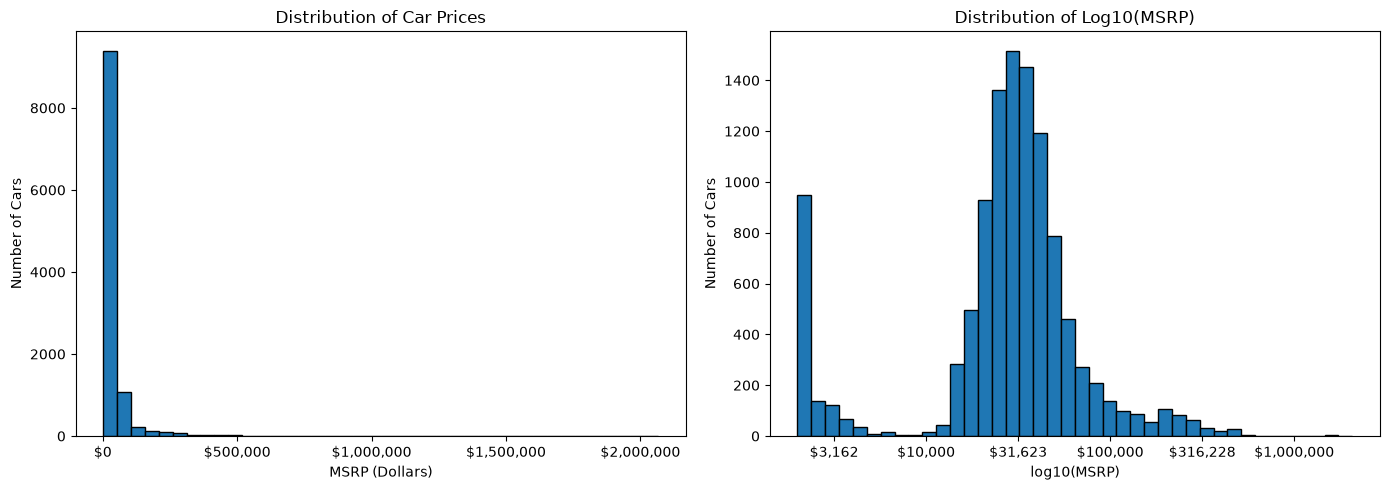

Share of cars above the mean: 2957


In [15]:
# a) mean and median
print("Mean:", clean["msrp"].mean().round(2))
print("Median:", clean["msrp"].median().round(2))

# b) two histograms side by side (plt.subplots(1, 2))
# Create two histograms

from matplotlib.ticker import FuncFormatter
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram 1: MSRP in dollars
axes[0].hist(clean["msrp"], bins=40, edgecolor="black")
axes[0].set_title("Distribution of Car Prices")
axes[0].set_xlabel("MSRP (Dollars)")
axes[0].set_ylabel("Number of Cars")

# Histogram 2: Log-transformed MSRP
axes[1].hist(np.log10(clean["msrp"]), bins=40, edgecolor="black")
axes[1].set_title("Distribution of Log10(MSRP)")
axes[1].set_xlabel("log10(MSRP)")
axes[1].set_ylabel("Number of Cars")

# Format x-axis as dollar amounts
axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${x:,.0f}')
)
axes[1].xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${10**x:,.0f}')
)


plt.tight_layout()
plt.show()

# c) share of cars above the mean
print("Share of cars above the mean:", (clean['msrp'] > clean['msrp'].mean()).sum())

**Answer:** 
a. The mean is bigger than the median because the distribution of car prices is right-skewed. A small number of very expensive luxury cars increase the mean, while the median is less affected by extreme values.

b. The distribution of cars in the first historgram is very right skewed. The cars are mostly within an affordable range, with a few luxury cars as outliers. The logramithic histogram is more evenly spread from the middle as the higher and lower prices are more condensed. 

c. 2957

d. The price I would use on the homepage is the median as it better represents the average value of the cars and isn't affected by the extreme values like the mean was. 

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [16]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only

clean_2017 = clean[clean["year"] == 2017]
print(clean_2017.groupby("vehicle_size")["highway_mpg"].agg(["mean", "std"]), "\n")


# b) z = (value - class mean) / class std
civic_2017 = (42 - 31.301181 )/ 8.083992
volvo_2017 = (34 - 22.956710 )/ 3.498724

print(f"Z-score for Civic 2017: {civic_2017:.2f}")
print(f"Z-score for Volvo 2017: {volvo_2017:.2f}")

                   mean       std
vehicle_size                     
Compact       31.301181  8.083992
Large         22.956710  3.498724
Midsize       29.356467  5.426434 

Z-score for Civic 2017: 1.32
Z-score for Volvo 2017: 3.16


**Answer:** The Volvo has a larger positive deviation from it's group mean compared to the Civic. That means with regards to it's size, the Volvo is more fuel efficient. 

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

MSRP median for 2017: 36710.0
95% confidence interval for MSRP median: [35890.0, 37720.0]


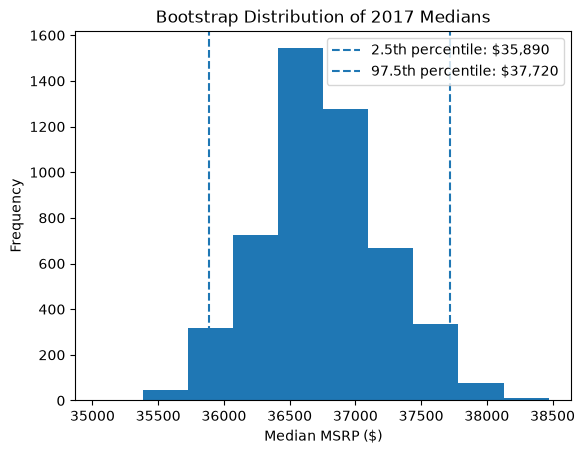

In [17]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    medians = []
    for _ in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        medians.append(np.median(sample))
    return np.array(medians)

# a, b)
msrp_median = clean_2017["msrp"].median()
print(f"MSRP median for 2017: {msrp_median}")

#bootstrap it
bootstrap_medians = bootstrap_median(clean_2017["msrp"])

lower = np.percentile(bootstrap_medians, 2.5)
upper = np.percentile(bootstrap_medians, 97.5)
print(f"95% confidence interval for MSRP median: [{lower}, {upper}]")

# Plot the bootstrap medians
plt.hist(bootstrap_medians)

plt.axvline(lower, linestyle="--", label=f"2.5th percentile: ${lower:,.0f}")
plt.axvline(upper, linestyle="--", label=f"97.5th percentile: ${upper:,.0f}")

plt.xlabel("Median MSRP ($)")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of 2017 Medians")
plt.legend()
plt.show()


95% confidence interval for Subaru MSRP median: [23995.0, 28840.0]


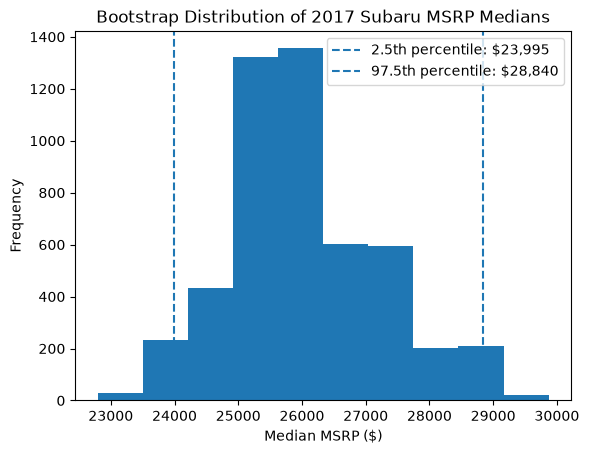

In [18]:
# c)
#clean_2017["make"].value_counts() ran this to choose subaru

subaru_2017 = clean_2017[clean_2017["make"] == "Subaru"]
bootstrap_medians = bootstrap_median(subaru_2017["msrp"], n_boot=5000)

lower = np.percentile(bootstrap_medians, 2.5)
upper = np.percentile(bootstrap_medians, 97.5)
print(f"95% confidence interval for Subaru MSRP median: [{lower}, {upper}]")

# Plot the bootstrap medians
plt.hist(bootstrap_medians)
plt.axvline(lower, linestyle="--", label=f"2.5th percentile: ${lower:,.0f}")
plt.axvline(upper, linestyle="--", label=f"97.5th percentile: ${upper:,.0f}")

plt.xlabel("Median MSRP ($)")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of 2017 Subaru MSRP Medians")
plt.legend()
plt.show()


**Answer:** 

c. The subaru bootstrap interval is wider, as indicated by the dotted axis lines. There are less values to calculate with, so the median is calculated with less precision. 

d. The median of the MSRP value of our cars in 2017 is within the range of $35879.75 to $37720.00. Its like the average values of our cars. 


---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

Sample size: 508
Mean MPG: 31.3


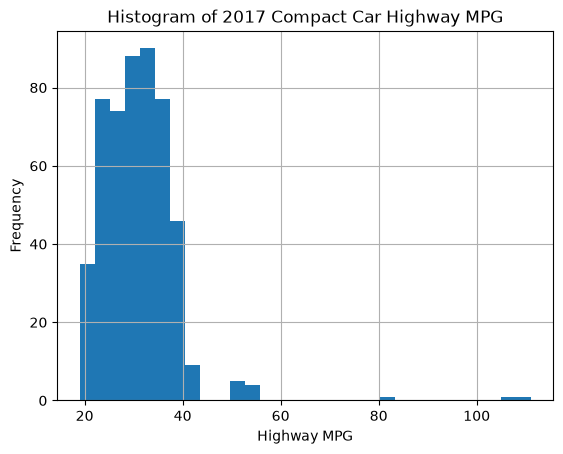

In [24]:

# b) sample: 2017 compact cars (MPG you trust); n, mean, histogram
compact_2017 = clean_2017[clean_2017["vehicle_size"] == "Compact"]

print("Sample size:", compact_2017.shape[0])
print("Mean MPG:", compact_2017["highway_mpg"].mean().round(2))

compact_2017["highway_mpg"].hist(bins=30)
plt.xlabel("Highway MPG")
plt.ylabel("Frequency")
plt.title("Histogram of 2017 Compact Car Highway MPG")
plt.show()


In [28]:
# c) one-sample t-test vs 30

result = stats.ttest_1samp(compact_2017["highway_mpg"], 30, alternative="greater")

print("Mean", compact_2017["highway_mpg"].mean().round(2))
print("T-test result:", result.statistic)
print("P-value:", result.pvalue)


Mean 31.3
T-test result: 3.6278033016104
P-value: 0.00015739635401304985


In [34]:

# d) rows per make+model, then one row per model and retest
make_model_counts = compact_2017.groupby(["make", "model"]).size()
print("Rows per make + model: \n", make_model_counts)

compact_models = (
    compact_2017.groupby(["make", "model"], as_index=False)
    ["highway_mpg"]
    .mean()
)

result_new = stats.ttest_1samp(compact_models["highway_mpg"], 30, alternative="greater")
print("Mean: ", compact_models["highway_mpg"].mean().round(2))
print("T-test result: ", result_new.statistic)
print("P-value: ", result_new.pvalue)




Rows per make + model: 
 make        model          
Acura       ILX                 6
            NSX                 1
Audi        A3                 12
            Q3                  6
            R8                  2
                               ..
Volkswagen  Golf Alltrack       5
            Golf GTI           10
            Golf R              4
            Golf SportWagen     4
            Tiguan              8
Length: 87, dtype: int64
Mean:  33.15
T-test result:  2.5604617582222837
P-value:  0.0060995814895970285


**Answer:**

a. Ho is the mean of the compact vehicles in 2017 with highway mpg less than or equal to 30 mpg, while Ha is the mean of compact vehicles in 2017 with a highway mpg greater than 30 mpg. This is a one-sided (right-tailed) test because marketing wants evidence that the mean MPG is over 30, not merely different from 30.

b. The sample size is large enough to do a t-test, and the graph is well distributed. There could be outlier values that affect the result but otherwise it is good. 

c. The p-value suggests that the mean highway mpg exceeds 30 mpg. 

d. After averaging each row and running the t-test again, we get about 0.006, greater than the value of 0.0001.So even when each model is given equal weight, the value is less than p-value of 0.05, showing the average is statistically higher than the average 30 mpg. I trust this current model level result, because it gives each model equal weight. 

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [ ]:
# a) compare median MSRP by transmission type
print("Median MSRP by transmission type:")
print(clean.groupby("transmission_type")["msrp"].median().round(2))


# b) compare year by transmission type
print("Year by transmission type:")
print(clean.groupby("transmission_type")["year"].median())

Median MSRP by transmission type:
transmission_type
AUTOMATED_MANUAL    43500.0
AUTOMATIC           33025.0
DIRECT_DRIVE        27875.0
MANUAL              19342.5
Name: msrp, dtype: float64
Year by transmission type:
transmission_type
AUTOMATED_MANUAL    2015.0
AUTOMATIC           2015.0
DIRECT_DRIVE        2016.0
MANUAL              2008.0
Name: year, dtype: float64


In [46]:

# c) compare 2015-2017 medians overall and within each vehicle_size
clean_two_years = clean[clean["year"].between(2015, 2017)]

#overall median 
print("Overall median MSRP: ", clean_two_years["msrp"].median().round(2))

# compare medians by vehicle size
print("Median MSRP by vehicle size for 2015-2017:")
print(clean_two_years.groupby("vehicle_size")["msrp"].median().round(2))

# compare 2015-2017 medians within each transmission type
auto = clean_two_years[(clean_two_years["transmission_type"] == "AUTOMATIC") & (clean_two_years["vehicle_size"] == "Compact")]["msrp"]
manual = clean_two_years[(clean_two_years["transmission_type"] == "MANUAL") & (clean_two_years["vehicle_size"] == "Compact")]["msrp"]

print("Auto Compact Median MSRP: ", auto.median().round(2))
print("Manual Compact Median MSRP: ", manual.median().round(2))

result = stats.mannwhitneyu(auto, manual)
print("Mann-Whitney U test result:", result.statistic)
print("P-value:", result.pvalue)

Overall median MSRP:  36090.0
Median MSRP by vehicle size for 2015-2017:
vehicle_size
Compact    27090.0
Large      44595.0
Midsize    37452.5
Name: msrp, dtype: float64
Auto Compact Median MSRP:  25995.0
Manual Compact Median MSRP:  25860.0
Mann-Whitney U test result: 315961.0
P-value: 0.1990381369881946


**Answer:**

a. The manual cars are cheaper

b. The manual cars have a much older average year than automatic, which could be a heavy factor in the pricing difference.

c. The medians of auto cars and manual cars are $25995.0 and $25860.0 show the auto vehicles are higher priced overall, but not to a very significant amount. Since the p-value from the U-Test is above 0.05, it means there isn't a statistically signififcant difference between the MSRP prices of a manual and automatic compact vehicle in the years 2015-2017. 

d. Manuals tend to be of an older model and not significantly cheaper than auto vehicles of the same age, so I would not recommend putting an intiative behind advertising manual cars. 

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [52]:
# a) Welch t-test, 4-door vs 2-door

four_door = clean[clean["number_of_doors"] == 4]["msrp"]
two_door = clean[clean["number_of_doors"] == 2]["msrp"]

print("4-door Median MSRP: ", four_door.median().round(2))
print("2-door Median MSRP: ", two_door.median().round(2))

result = stats.ttest_ind(four_door, two_door, equal_var=False)
print("Welch t-test result:", result.statistic.round(4))
print("P-value:", result.pvalue)

4-door Median MSRP:  31200.0
2-door Median MSRP:  29450.0
Welch t-test result: -11.3316
P-value: 3.2890859676639677e-29


In [ ]:

# b) yearly gas cost = miles * price_per_gallon / mpg
#  Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

four_door_mpg = clean[clean["number_of_doors"] == 4]["highway_mpg"]
two_door_mpg = clean[clean["number_of_doors"] == 2]["highway_mpg"]

yearly_gas_cost_four_door = 12000 * 3.5 / four_door_mpg.mean()
yearly_gas_cost_two_door = 12000 * 3.5 / two_door_mpg.mean()
print("Average yearly gas cost for 4-door driver: ", yearly_gas_cost_four_door.round(2))
print("Average yearly gas cost for 2-door driver: ", yearly_gas_cost_two_door.round(2))


print("Average yearly savings for 4-door driver: ", (yearly_gas_cost_two_door - yearly_gas_cost_four_door).round(2))


Average yearly gas cost for 4-door driver:  1559.07
Average yearly gas cost for 2-door driver:  1661.93
Average yearly savings for 4-door driver:  102.87


In [57]:

# c) simulation
n_sims, hits = 1000, 0
for _ in range(n_sims):
    four_door_sample = rng.choice(four_door_mpg, 30, replace=False)
    two_door_sample = rng.choice(two_door_mpg, 30, replace=False)
    # sample 30 from each group with rng.choice(..., 30, replace=False), run the test, count p < 0.05
    result = stats.ttest_ind(four_door_sample, two_door_sample)
    if result.pvalue < 0.05:
        hits += 1
print("Proportion of significant results: ", hits / n_sims)

Proportion of significant results:  0.166


**Answer:**

a. The median for 4-door vehicles  is $31200.00, about 2 thousand more than 2-door vehicles at $29450.00. The p-value is at 3.2 * 10^-23, making it much lower than the 0.05 value. This suggests a statically significant difference between the mean values.

b. They save an average of $102.87

c. Proportion of significant results:  0.166

d. I think it's a grey area. Four doors cost significantly more. While the value of saving on fuel prices is there,  only 16 percent of the simulations gave a statistically significant difference between four door vehicles and 2 door vehicles.

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:** Manual cars do not cost significantly less. While the median values for auto and manual cars show that manual cars are slightly cheaper, this is because the manual cars selection consist of older models. When comparing pools of cars in more rescent years, we got a p-value of 0.2, higher than 0.05. This means that there is no statistically significant difference in prices when looking at auto and manual cars of similar years. I did notice the four door cars tend to have higher pricings overall than two door cars, and that electric vehicles tend to have much higher mpgs than any other vehicle. One limitation is that there are many rows that are duplicates or have what appear to be placeholder values which can lead to skewed results. 

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [ ]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [ ]:
# S2